[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/tayalmanan28/MuJoCo-Tutorial/blob/main/tutorial/10_troubleshooting.ipynb)

# Tutorial 10: Troubleshooting & Common Mistakes

A survival guide for the errors every MuJoCo beginner hits.

In [1]:
!pip install -q mujoco mediapy

In [2]:
import os
os.environ["MUJOCO_GL"] = "egl"
import mujoco
import numpy as np
import mediapy as media

---
## Problem 1: Black screen when rendering

**Symptom:** You render an image but it's all black (or partially black).

**Cause:** You didn't call `mj_forward()` after setting `qpos` manually, so derived quantities (like Cartesian positions of geoms) haven't been computed yet.

❌ Without mj_forward,✅ With mj_forward

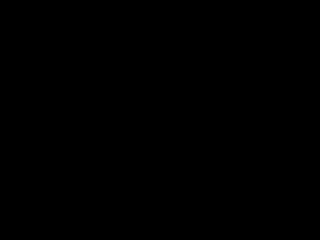
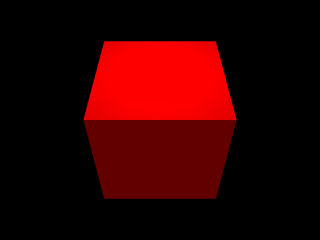

In [3]:
xml = """
<mujoco>
  <worldbody>
    <light pos="0 0 1.5"/>
    <geom type="box" size=".2 .2 .2" pos="0 0 .2" rgba="1 0 0 1"/>
  </worldbody>
</mujoco>
"""
model = mujoco.MjModel.from_xml_string(xml)
data = mujoco.MjData(model)
renderer = mujoco.Renderer(model)

# ❌ WRONG: rendering without mj_forward
renderer.update_scene(data)
bad_image = renderer.render().copy()

# ✅ CORRECT: call mj_forward first
mujoco.mj_forward(model, data)
renderer.update_scene(data)
good_image = renderer.render().copy()

renderer.close()
media.show_images([bad_image, good_image], titles=['❌ Without mj_forward', '✅ With mj_forward'])

**Fix:** Always call `mujoco.mj_forward(model, data)` after manually setting `data.qpos` or `data.qvel`. If you're calling `mj_step()` in a loop, this is done automatically.

---
## Problem 2: Simulation "explodes" (NaN or huge values)

**Symptom:** Positions become `inf` or `nan`, objects fly to infinity.

**Common causes:**
1. Timestep too large for the model
2. Extremely large control forces
3. Penetrating geoms at initialization

In [23]:
# Example: timestep too large
xml_stiff = """
<mujoco>
  <option timestep="0.1" gravity="0 0 -9.81"/>  <!-- 0.1s is way too large! -->
  <worldbody>
    <geom type="plane" size="5 5 0.1"/>
    <body pos="0 0 0.5">
      <joint type="free"/>
      <geom type="sphere" size="0.1" mass="1"/>
    </body>
  </worldbody>
</mujoco>
"""

m = mujoco.MjModel.from_xml_string(xml_stiff)
d = mujoco.MjData(m)

print("Simulating with dt=0.1 (dangerously large):")
for i in range(20):
    mujoco.mj_step(m, d)
    z = d.qpos[2]
    if abs(z) > 100 or np.isnan(z):
        print(f"  Step {i}: z = {z} ← EXPLODED!")
        break
    elif i < 5 or i % 5 == 0:
        print(f"  Step {i}: z = {z:.4f}")

print("\n✅ Fix: Use timestep ≤ 0.005 (default is 0.002)")

Simulating with dt=0.1 (dangerously large):
  Step 0: z = 0.4019
  Step 1: z = 0.2057
  Step 2: z = -0.0886
  Step 3: z = -0.0464
  Step 4: z = -0.0147
  Step 5: z = 0.0091
  Step 10: z = 0.0635
  Step 15: z = 0.0764

✅ Fix: Use timestep ≤ 0.005 (default is 0.002)


In [5]:
# How to detect instability in your code:
def check_simulation_health(data):
    """Call this periodically to catch explosions early."""
    if np.any(np.isnan(data.qpos)) or np.any(np.isnan(data.qvel)):
        return "NaN detected! Simulation diverged."
    if np.any(np.abs(data.qpos) > 1e6):
        return "Extreme positions! Likely unstable."
    if np.any(np.abs(data.qvel) > 1e6):
        return "Extreme velocities! Likely unstable."
    return "OK"

print("Use this helper to catch problems early!")
print(f"Health check: {check_simulation_health(d)}")

Use this helper to catch problems early!
Health check: OK


---
## Problem 3: Objects pass through each other

**Symptom:** Bodies that should collide don't.

**Common causes:**
1. Mismatched `contype`/`conaffinity` (collision filtering)
2. Geoms in the same body don't collide with each other by default
3. Objects starting in deep penetration

In [25]:
# Collision happens when: (geomA.contype & geomB.conaffinity) OR (geomB.contype & geomA.conaffinity)
# Default: contype=1, conaffinity=1 → everything collides with everything

# If you accidentally set contype=0:
xml_no_collide = """
<mujoco>
  <option gravity="0 0 -9.81"/>
  <worldbody>
    <light pos="0 0 3"/>
    <geom type="plane" size="2 2 0.1"/>  <!-- contype=1 by default -->
    <body pos="0 0 1">
      <joint type="free"/>
      <geom type="sphere" size="0.1" contype="0" conaffinity="1"/>  <!-- ❌ won't collide! -->
    </body>
  </worldbody>
</mujoco>
"""

m = mujoco.MjModel.from_xml_string(xml_no_collide)
d = mujoco.MjData(m)

# The ball falls through the floor
for _ in range(500):
    mujoco.mj_step(m, d)
print(f"Ball fell to z={d.qpos[2]:.2f} (below the ground!)")
print("\n✅ Fix: Ensure colliding geoms have matching contype & conaffinity")
print("   Default (contype=1, conaffinity=1) works for most cases.")

Ball fell to z=0.10 (below the ground!)

✅ Fix: Ensure colliding geoms have matching contype & conaffinity
   Default (contype=1, conaffinity=1) works for most cases.


---
## Problem 4: Robot doesn't move (control has no effect)

**Symptom:** You set `data.ctrl` but nothing happens.

**Common causes:**
1. Forgot to add `<actuator>` in XML
2. Control range is too small
3. Joint has high damping that kills all motion
4. Setting ctrl outside the control loop (only once)

In [7]:
# Debugging checklist:
xml_debug = """
<mujoco>
  <worldbody>
    <body pos="0 0 1">
      <joint name="j1" type="hinge" axis="0 1 0" damping="0.1"/>
      <geom type="capsule" fromto="0 0 0 0 0 -0.5" size="0.03" mass="1"/>
    </body>
  </worldbody>
  <actuator>
    <motor name="m1" joint="j1" ctrlrange="-5 5" gear="1"/>
  </actuator>
</mujoco>
"""
m = mujoco.MjModel.from_xml_string(xml_debug)
d = mujoco.MjData(m)

print("=== Control Debugging Checklist ===")
print(f"  Number of actuators (model.nu): {m.nu}")
print(f"  Control range: {m.actuator_ctrlrange}")
print(f"  Actuator gear: {m.actuator_gear[:, 0]}")
print(f"  Joint damping: {m.jnt_stiffness}")
print(f"  data.ctrl shape: {d.ctrl.shape}")
print()
print("If nu=0, you forgot to add <actuator> in your XML!")
print("If ctrl has no effect, check gear and ctrlrange.")

=== Control Debugging Checklist ===
  Number of actuators (model.nu): 1
  Control range: [[-5.  5.]]
  Actuator gear: [1.]
  Joint damping: [0.]
  data.ctrl shape: (1,)

If nu=0, you forgot to add <actuator> in your XML!
If ctrl has no effect, check gear and ctrlrange.


---
## Problem 5: Model won't load (XML errors)

**Common XML mistakes:**

In [8]:
# Example: common XML mistakes and how to fix them

bad_examples = {
    "Missing closing tag": '<mujoco><worldbody><geom type="sphere"/></mujoco>',
    "Actuator references nonexistent joint": '''
        <mujoco>
          <worldbody><body><joint name="j1"/><geom size="0.1"/></body></worldbody>
          <actuator><motor joint="wrong_name"/></actuator>
        </mujoco>''',
    "Body outside worldbody": '<mujoco><body><geom size="0.1"/></body></mujoco>',
}

for name, xml in bad_examples.items():
    try:
        mujoco.MjModel.from_xml_string(xml)
        print(f"  {name}: no error (unexpected)")
    except Exception as e:
        # Get first line of error
        error_msg = str(e).split('\n')[0][:80]
        print(f"❌ {name}")
        print(f"   Error: {error_msg}")
        print()

❌ Missing closing tag
   Error: XML parse error 14:

❌ Actuator references nonexistent joint
   Error: Error: unknown transmission target 'wrong_name' for actuator id = 0

  Body outside worldbody: no error (unexpected)


**Tips for XML debugging:**
1. Start with a minimal working model and add things one at a time
2. MuJoCo's error messages tell you the line number — read them!
3. Use an XML validator or IDE with XML highlighting
4. Common typo: `fromto` needs 6 numbers (x1 y1 z1 x2 y2 z2)

---
## Problem 6: Rendering works locally but not on a server/Colab

**Symptom:** `mujoco.viewer.launch()` fails with display errors.

**Cause:** Interactive viewer needs a display (GUI). Servers/Colab don't have one.

**Fix:** Use `mujoco.Renderer` (offscreen) instead:

In [9]:
import os

# Check if we have a display
has_display = 'DISPLAY' in os.environ or os.environ.get('MUJOCO_GL') == 'egl'

print("Rendering options:")
print(f"  Display available: {has_display}")
print()
print("  Local machine (has display):")
print("    → mujoco.viewer.launch(model, data)      # interactive 3D viewer")
print("    → mujoco.viewer.launch_passive(model, data)  # non-blocking")
print()
print("  Server/Colab (no display):")
print("    → renderer = mujoco.Renderer(model)      # offscreen")
print("    → renderer.render()                       # returns numpy array")
print("    → media.show_image(pixels)                # display in notebook")
print()
print("  Tip: Set MUJOCO_GL=egl for headless GPU rendering:")
print("    os.environ['MUJOCO_GL'] = 'egl'  # before importing mujoco")

Rendering options:
  Display available: True

  Local machine (has display):
    → mujoco.viewer.launch(model, data)      # interactive 3D viewer
    → mujoco.viewer.launch_passive(model, data)  # non-blocking

  Server/Colab (no display):
    → renderer = mujoco.Renderer(model)      # offscreen
    → renderer.render()                       # returns numpy array
    → media.show_image(pixels)                # display in notebook

  Tip: Set MUJOCO_GL=egl for headless GPU rendering:
    os.environ['MUJOCO_GL'] = 'egl'  # before importing mujoco


---
## Problem 7: Performance is slow

**Tips for speed:**

In [10]:
import time

xml = """
<mujoco>
  <option timestep="0.002"/>
  <worldbody>
    <geom type="plane" size="5 5 0.1"/>
    <body pos="0 0 1"><joint type="free"/><geom type="sphere" size="0.1"/></body>
  </worldbody>
</mujoco>
"""
m = mujoco.MjModel.from_xml_string(xml)
d = mujoco.MjData(m)

# Benchmark
n_steps = 100_000
t0 = time.time()
for _ in range(n_steps):
    mujoco.mj_step(m, d)
elapsed = time.time() - t0

sim_time = n_steps * m.opt.timestep
print(f"{n_steps:,} steps in {elapsed:.2f}s")
print(f"Simulated {sim_time:.0f}s of physics in {elapsed:.2f}s wall time")
print(f"Speed: {sim_time/elapsed:.0f}× real-time")
print()
print("Performance tips:")
print("  1. Don't render every step — render at 30-60 fps only")
print("  2. Use larger timestep if stable (0.005 instead of 0.002)")
print("  3. Reduce model complexity (fewer geoms/contacts)")
print("  4. For RL: use MJX (GPU) to batch thousands of envs")
print("  5. Avoid Python loops around mj_step — use native callbacks")

100,000 steps in 0.79s
Simulated 200s of physics in 0.79s wall time
Speed: 253× real-time

Performance tips:
  1. Don't render every step — render at 30-60 fps only
  2. Use larger timestep if stable (0.005 instead of 0.002)
  3. Reduce model complexity (fewer geoms/contacts)
  4. For RL: use MJX (GPU) to batch thousands of envs
  5. Avoid Python loops around mj_step — use native callbacks


---
## Quick Reference: Common Operations

```python
# ─── Setup ───
model = mujoco.MjModel.from_xml_string(xml)   # or from_xml_path("file.xml")
data = mujoco.MjData(model)

# ─── Reset ───
mujoco.mj_resetData(model, data)               # reset to initial state
data.qpos[0] = 1.5                             # then set custom state
mujoco.mj_forward(model, data)                 # propagate (IMPORTANT!)

# ─── Simulate ───
data.ctrl[0] = 1.0                             # set control
mujoco.mj_step(model, data)                    # advance one timestep

# ─── Read state ───
pos = data.qpos[:]                             # all positions
vel = data.qvel[:]                             # all velocities
t = data.time                                  # current sim time

# ─── Named access ───
model.joint('shoulder').id                     # joint ID by name
data.body('robot').xpos                        # body position in world
data.site('end_effector').xpos                 # site position

# ─── Render ───
renderer = mujoco.Renderer(model, height=480, width=640)
mujoco.mj_forward(model, data)                 # needed before first render
renderer.update_scene(data)
pixels = renderer.render()                     # numpy array (H, W, 3)
renderer.close()                               # free resources

# ─── Contacts ───
n = data.ncon                                  # number of active contacts
force = np.zeros(6)
mujoco.mj_contactForce(model, data, 0, force)  # force at contact 0
```

---
## Still stuck?

1. **Official docs:** [mujoco.readthedocs.io](https://mujoco.readthedocs.io/)
2. **GitHub issues:** [github.com/google-deepmind/mujoco/issues](https://github.com/google-deepmind/mujoco/issues)
3. **XML reference:** [mujoco.readthedocs.io/en/stable/XMLreference.html](https://mujoco.readthedocs.io/en/stable/XMLreference.html)
4. **Python bindings:** [mujoco.readthedocs.io/en/stable/python.html](https://mujoco.readthedocs.io/en/stable/python.html)